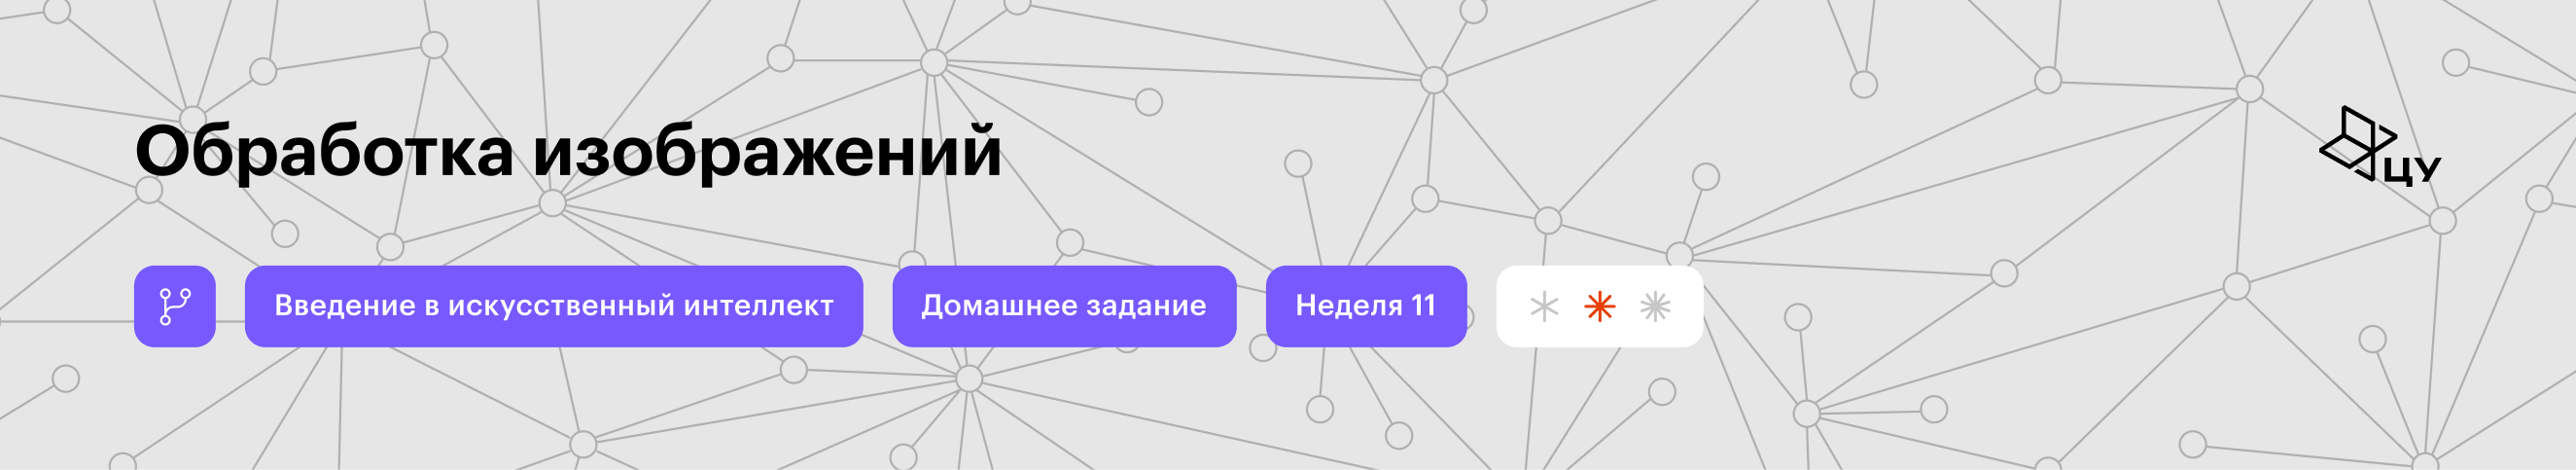

# Домашнее задание по теме «Обработка изображений»

В этом домашнем задании ты поработаешь с изображениями и исследуешь, как искажения влияют на их качество и на работу простой модели классификации.

Тебе предстоит:

- добавить к изображению Gaussian noise и Salt & Pepper noise;
- реализовать MSE, MAE и PSNR и исследовать их зависимость от уровня шума;
- применить сглаживающие фильтры и сравнить результаты визуально и с помощью метрик;
- обучить логистическую регрессию на изображениях цифр и проверить её чувствительность к сдвигу.

Всего **4 задания, 10 баллов**: 3 + 2 + 3 + 2. В эталонной версии после блоков «Твоё решение» приведены решения и выводы.


> ### Правила домашнего задания
> 1. Нельзя удалять существующие ячейки кода.
> 2. Можно добавлять и дописывать свои ячейки.
> 3. Место, куда тебе нужно написать код, помечается комментарием.
> 4. Ответ без кода, который подтвердит твоё решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется и нужно сделать вывод из известных данных.
> 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.
> 6. Все графики подписывай так, чтобы можно было легко понять их суть. Избегай слишком мелкого или крупного текста, подписывай оси на одном языке.
> 7. В выводах опирайся на полученные изображения, таблицы и графики. Для случайных преобразований фиксируй seed.


## Импорт пакетов

Ноутбук рассчитан на Python 3 и Google Colab / Jupyter. Если какой-то библиотеки нет, установи её командой `%pip install numpy pandas matplotlib opencv-python-headless scikit-learn` в отдельной ячейке.


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['image.cmap'] = 'gray'


## Подготовка данных

В заданиях 1–3 используй одно и то же изображение `kodak/kodim07.png` из датасета Kodak, как в исходном домашнем задании по свёрткам. Ячейка ниже скачает только этот файл, если его ещё нет рядом с ноутбуком. Для первого запуска нужен интернет.

Для задания 4 используется встроенный в `sklearn` датасет `digits`; отдельно скачивать его не нужно.


In [ ]:
image_path = Path('kodak/kodim07.png')
if not image_path.exists():
    image_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        'https://r0k.us/graphics/kodak/kodak/kodim07.png',
        image_path,
    )

print('Изображение для заданий 1–3:', image_path)


Изображение для заданий 1–3: kodak/kodim07.png


## Вспомогательная функция для визуализации результатов

Во всех сравнениях используй одну шкалу яркости: от 0 до 255. Функция ниже принимает numpy-массивы: grayscale или RGB. Цветное изображение, прочитанное через `cv2.imread`, перед показом нужно перевести из BGR в RGB.


In [ ]:
def plot_images(images, titles=None, fontsize=13, figsize=(16, 4), save_path=None):
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for i, image in enumerate(images):
        ax = axes[0, i]
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(image)
        ax.axis('off')
        if titles is not None:
            ax.set_title(titles[i], fontsize=fontsize)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight')
    plt.show()


### Задание 1. Добавление шума к изображению [3 балла]

В этом задании тебе нужно испортить изображение двумя различными способами.

#### Часть 1. Подготовка изображения [0,6 балла]

1. Прочитай `kodak/kodim07.png` и переведи изображение в формат grayscale.
2. Визуализируй исходное изображение. Сохрани его в переменной `img_gray`: это эталон для следующих заданий.

Для визуализации можно использовать функцию `plot_images` выше.

#### Часть 2. Gaussian noise [1,2 балла]

Добавь к изображению гауссовский шум:

$$
\varepsilon \sim \mathcal{N}(0, \sigma^2),
$$

где $\sigma$ — стандартное отклонение шума. Используй значения $10$, $20$, $40$.

1. Для каждого значения $\sigma$ сгенерируй шум такого же размера, что и изображение.
2. Прибавь шум к исходному изображению. До сложения переведи изображение в вещественный тип, чтобы избежать переполнения `uint8`.
3. Ограничь значения пикселей диапазоном $[0, 255]$ и приведи результат к типу `uint8`.
4. Визуализируй результаты рядом с исходным изображением.

#### Часть 3. Salt & Pepper noise [1,2 балла]

Добавь к изображению случайные чёрные и белые пиксели. Пусть вероятность искажения пикселя равна $p$. Используй значения $0{,}01$; $0{,}03$; $0{,}1$.

1. Для каждого значения $p$ скопируй исходное изображение.
2. Независимо для каждого пикселя: с вероятностью $p/2$ замени его на $0$, с вероятностью $p/2$ — на $255$, с вероятностью $1-p$ оставь без изменений. Один пиксель не должен одновременно попадать в обе группы.
3. Визуализируй результаты рядом с исходным изображением.

### Что должно получиться

Сохрани результаты в словари `gaussian_images` (ключ — $\sigma$) и `sp_images` (ключ — $p$). Добавь в каждый словарь уровень `0`, соответствующий копии исходного изображения без шума. Эти же массивы понадобятся в заданиях 2 и 3: заново генерировать шум там не нужно.

Для дальнейшего сравнения сохрани `gauss_noisy = gaussian_images[40]` и `sp_noisy = sp_images[0.1]`.

Кратко сравни, как визуально отличаются два типа шума и что меняется при увеличении его уровня.


#### Твоё решение


In [ ]:
img = cv2.imread(str(image_path))

# Напиши код здесь


Напиши выводы здесь.


### Задание 2. Метрики качества изображения и их зависимость от шума [2 балла]

Используй **те же** `img_gray`, `gaussian_images` и `sp_images`, которые получились в задании 1. Во всех сравнениях эталоном служит исходное изображение `img_gray`.

#### Часть 1. Реализация метрик [0,9 балла]

Самостоятельно реализуй три функции: `mse(reference, image)`, `mae(reference, image)`, `psnr(reference, image)` — по **0,3 балла** за каждую. Готовые реализации метрик использовать нельзя; операции NumPy использовать можно.

Для изображений $I$ и $J$ одинакового размера, содержащих $N$ значений пикселей:

$$
\operatorname{MSE}(I,J) = \frac{1}{N}\sum_{i=1}^{N}(I_i-J_i)^2,
$$

$$
\operatorname{MAE}(I,J) = \frac{1}{N}\sum_{i=1}^{N}|I_i-J_i|,
$$

$$
\operatorname{PSNR}(I,J) = 10\log_{10}\left(\frac{255^2}{\operatorname{MSE}(I,J)}\right).
$$

Вычисления веди в вещественном типе: вычитание массивов `uint8` приводит к переполнению. Здесь изображения имеют диапазон $[0,255]$, поэтому максимум в формуле PSNR всегда равен **255**, а не максимуму конкретного изображения. PSNR измеряется в децибелах (дБ).

Если MSE равна нулю, PSNR должна возвращать `np.inf`.

#### Часть 2. Проверка и сравнение изображений [0,3 балла]

1. Проверь метрики на паре одинаковых изображений: ожидаются MSE = 0, MAE = 0, PSNR = ∞.
2. Посчитай все три метрики для изображений `gauss_noisy` и `sp_noisy` относительно `img_gray`. Выведи результаты в таблице. Для каких метрик меньшее значение означает лучшее качество, а для какой — большее?

#### Часть 3. Зависимость от уровня шума [0,5 балла]

1. Посчитай MSE, MAE и PSNR для **всех** уровней шума из задания 1, включая уровень 0, и собери общую таблицу.
2. Для каждого типа шума построй три графика: MSE, MAE и PSNR от уровня шума. Для Gaussian noise по оси X отложи $\sigma$, для Salt & Pepper noise — $p$.
3. Бесконечное значение PSNR при нулевом шуме оставь в таблице, но не соединяй с конечными точками графика.

#### Часть 4. Анализ результатов [0,3 балла]

Ответь на вопросы.

- Как меняются MSE, MAE и PSNR при увеличении уровня каждого из двух типов шума?
- Почему при увеличении ошибки PSNR уменьшается?
- Совпадает ли численная оценка качества с визуальной? Достаточно ли одного числа, чтобы понять, какие детали изображения испорчены?

Сравнивать σ и p напрямую нельзя: это разные параметры, заданные в разных единицах. Исследуй зависимость отдельно для каждого типа шума.


#### Твоё решение


In [ ]:
def mse(reference, image):
    # Напиши код здесь
    pass


def mae(reference, image):
    # Напиши код здесь
    pass


def psnr(reference, image):
    # Напиши код здесь
    pass

# Напиши код проверки метрик, таблиц и графиков здесь


Напиши ответы здесь.


### Задание 3. Удаление шума [3 балла]

В этом задании тебе нужно убрать шум с изображений из задания 1: `gauss_noisy` ($\sigma=40$) и `sp_noisy` ($p=0{,}1$). Используй сохранённые массивы, чтобы все фильтры сравнивались на одинаковых искажениях.

#### Часть 1. Применение фильтров [1,5 балла]

Примени минимум три фильтра из списка — **по 0,5 балла за каждый**:

- Mean filter (`cv2.blur`);
- Gaussian filter (`cv2.GaussianBlur`);
- Median filter (`cv2.medianBlur`);
- Bilateral filter (`cv2.bilateralFilter`) — по желанию, без дополнительных баллов.

Для каждого выбранного фильтра:

- подбери параметры (размер ядра, σ и так далее); попробуй хотя бы два набора параметров;
- примени фильтр к **обоим** зашумлённым изображениям;
- визуализируй выбранный результат рядом с исходным и зашумлённым изображением;
- посчитай MSE, MAE и PSNR из задания 2 относительно `img_gray`.

При подборе параметров можно ориентироваться на MSE: это учебный эксперимент с доступным исходным изображением. Включи в итоговую таблицу также строку «Без фильтра», чтобы было видно, улучшилось ли качество. Лучшие параметры для двух типов шума могут различаться.

#### Часть 2. Сравнение результатов [1,5 балла]

Ответь на вопросы, используя изображения и таблицу метрик.

1. **[0,4 балла]** Какой фильтр лучше справился с Gaussian noise по MSE/PSNR? Совпадает ли вывод с визуальной оценкой?
2. **[0,4 балла]** Какой фильтр лучше справился с Salt & Pepper noise? Почему?
3. **[0,4 балла]** Какие фильтры сильнее размывают детали? Может ли уменьшение численной ошибки сопровождаться потерей мелких деталей?
4. **[0,3 балла]** Легко ли было подобрать параметры? Что меняется при увеличении размера ядра?


#### Твоё решение


In [ ]:
# Напиши код здесь


Напиши ответы здесь.


### Задание 4. Логистическая регрессия на `flatten` и чувствительность к сдвигу [2 балла]

Теперь перейди от обработки изображения к распознаванию рукописных цифр. В этом задании ты проверишь, насколько модель чувствительна к положению объекта на изображении.

Используй встроенный датасет `digits` из `sklearn` и оставь только цифры `3` и `8`. Каждое изображение имеет размер `8 × 8`, а яркость пикселей лежит в диапазоне `[0, 16]`. В готовой ячейке ниже данные уже нормированы в диапазон `[0, 1]` и подготовлены в двух формах:

- `X_img` — изображения размера `8 × 8`;
- `X_flat` — те же изображения, развёрнутые в векторы длины `64`;
- `y` — соответствующие метки классов.

Обучи логистическую регрессию на признаках `flatten`.

Выполни следующие шаги.

1. **[0,1 балла]** Разбей данные на train и test (`test_size=0.25`, `stratify=y`, `random_state=42`). Разделяй `X_img`, `X_flat` и `y` совместно, чтобы изображения и метки оставались согласованными.
2. **[0,4 балла]** Обучи `LogisticRegression` на `X_train_flat`. Установи `max_iter=2000` и `random_state=42`.
3. **[0,2 балла]** Посчитай accuracy на обычном тесте.
4. **[0,3 балла]** Создай новую версию тестовых изображений: сдвинь каждую цифру вправо на один пиксель с заполнением освободившегося столбца нулями. Правый столбец обрежь. Не используй циклический перенос пикселей.
5. **[0,2 балла]** Снова посчитай accuracy той же обученной модели — уже на сдвинутом тесте. Метки классов остаются прежними; переобучать модель не нужно.
6. **[0,3 балла]** Построй матрицы ошибок (`confusion matrix`) для обычного и сдвинутого теста.
7. **[0,1 балла]** Покажи несколько примеров ошибок на сдвинутом тесте. Подпиши истинный и предсказанный классы.

**[0,4 балла]** После этого ответь на вопросы.

- Почему модель на `flatten` может хорошо работать на исходных изображениях?
- Как изменилось качество после сдвига? Почему даже сдвиг на один пиксель может ухудшить распознавание, хотя человек по-прежнему видит ту же цифру?
- Какую информацию сохраняет представление `flatten` и почему оно чувствительно к положению штрихов?

In [ ]:
# Подготовка данных для задания 4: эта ячейка уже готова
digits = load_digits()
selected_classes = [3, 8]
mask = np.isin(digits.target, selected_classes)

X_img = digits.images[mask].astype(np.float64) / 16.0
y = digits.target[mask]
X_flat = X_img.reshape(len(X_img), -1)

print("Форма массива изображений:", X_img.shape)
print("Форма массива flatten-признаков:", X_flat.shape)
print("Классы:", np.unique(y))

Форма массива изображений: (357, 8, 8)
Форма массива flatten-признаков: (357, 64)
Классы: [3 8]


#### Твоё решение

In [ ]:
# Напиши код здесь

Напиши выводы здесь.